In [1]:
import ast
from collections import Counter
from pathlib import Path
from typing import Iterable, Optional, Union

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer

In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.2

In [3]:
COLAB_DIR = Path('/content/drive/MyDrive')
KAGGLE_DIR = Path('/kaggle/input')
LOCAL_DIR = Path('../')

try:
    import google.colab

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    import kaggle_secrets

    IN_KAGGLE = True
except ImportError:
    IN_KAGGLE = False

if IN_COLAB:
    DATA_DIR = COLAB_DIR / 'data'
    MODELS_DIR = COLAB_DIR / 'models'
elif IN_KAGGLE:
    DATA_DIR = KAGGLE_DIR
    MODELS_DIR = KAGGLE_DIR
else:
    DATA_DIR = LOCAL_DIR / 'data'
    MODELS_DIR = LOCAL_DIR / 'models'

In [4]:
TWEETS_CSV = DATA_DIR / 'tweets-dataset-for-cyberattack-detection' / 'tweets_final.csv'

In [5]:
filter_df = pd.read_csv(filepath_or_buffer=TWEETS_CSV)
filter_df.dropna(subset=['relevant'])

print(f"There are {filter_df.shape[0]} tweets")
filter_df.head()

There are 21368 tweets


,_id,date,id,relevant,text,tweet,type,watson,annotation,urls,destination_url,valid_certificate
0,b'5b88752abb325e65390af240',2018-08-30 22:52:25+00:00,1035299228984041472,False,Best way to build empathy is through honesty a...,{'created_at': 'Thu Aug 30 22:52:25 +0000 2018...,vulnerability,"{'usage': {'text_units': 1, 'text_characters':...",irrelevant,[],NaN,NaN
1,b'5b8875d5bb325e65a22cf81b',2018-08-30 22:55:15+00:00,1035299941932036096,False,Cryptocurrency Scams Replacing Ransomware as A...,{'created_at': 'Thu Aug 30 22:55:15 +0000 2018...,ransomware,"{'usage': {'text_units': 1, 'text_characters':...",business,['https://ubm.io/2MCQwfg'],https://www.darkreading.com/endpoint-security,False
2,b'5b88768dbb325e65fa7e78e3',2018-08-30 22:58:20+00:00,1035300715470757889,False,Cryptocurrency Scams Replacing Ransomware as A...,{'created_at': 'Thu Aug 30 22:58:20 +0000 2018...,ransomware,"{'usage': {'text_units': 1, 'text_characters':...",business,['http://quantus.biz/security/2018/08/30/crypt...,http://www.quantusintel.group/,True
3,b'5b8876f9bb325e65fa7e78e4',2018-08-30 23:00:08+00:00,1035301167952211969,True,Protect your customers access Prestashop Ant...,{'created_at': 'Thu Aug 30 23:00:08 +0000 2018...,ddos,"{'usage': {'text_units': 1, 'text_characters':...",threat,['http://addons.prestashop.com/en/23513-anti-d...,https://addons.prestashop.com/en/23513-anti-dd...,True
4,b'5b8876f9bb325e65fa7e78e5',2018-08-30 23:00:09+00:00,1035301173178249217,True,Data leak from Huazhu Hotels may affect 130 mi...,{'created_at': 'Thu Aug 30 23:00:09 +0000 2018...,leak,"{'usage': {'text_units': 1, 'text_characters':...",threat,['http://www.hotelmanagement.net/tech/data-lea...,http://www.hotelmanagement.net/tech/data-leak-...,True


In [6]:
X_train_val, X_test = train_test_split(
    filter_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=filter_df['relevant']
)

X_train_val.shape, X_test.shape

((17094, 12), (4274, 12))

In [7]:
with open(DATA_DIR / 'tweets-dataset' / 'filter_train.csv', 'wb') as f:
    X_train_val.to_csv(path_or_buf=f)

with open(DATA_DIR / 'tweets-dataset' / 'filter_test.csv', 'wb') as f:
    X_test.to_csv(path_or_buf=f)

In [8]:
X_train_val = pd.read_csv(filepath_or_buffer=DATA_DIR / 'tweets-dataset' / 'filter_train.csv')
X_test = pd.read_csv(filepath_or_buffer=DATA_DIR / 'tweets-dataset' / 'filter_test.csv')

X_train_val.shape, X_test.shape

((17094, 13), (4274, 13))

In [9]:
def build_tree(categories: list[dict]) -> dict:
    """
    Build a tree-like structure (nested dictionary) from category labels.

    Parameters
    ----------
    categories
        A list of categories, where each category has a 'label' key that contains a path-like string.

    Returns
    -------
    tree
        A nested dictionary representing the tree structure.
    """
    tree = {}

    for category in categories:
        current = tree

        for part in category['label'].strip('/').split('/'):
            current = current.setdefault(part, {})

    return tree
    
def extract_keys(d: Union[dict, object], path: Optional[Iterable] = None) -> list:
    """
    Recursively extract keys from a dictionary, building paths as a list.

    Parameters
    ----------
    d
        The dictionary to extract keys from.
    path
        A list to accumulate the path, default is None.

    Returns
    -------
    path
        A list of paths representing keys in the dictionary.
    """
    if path is None:
        path = []

    if isinstance(d, dict):
        for key, value in d.items():
            path = extract_keys(d=value, path=path + [key])
    else:
        path = [d]

    return path

def map_targets(watson_list, fix_targets):
    targets = set(fix_targets.keys()) & set(watson_list)
    mapped_targets = {fix_targets[category] for category in targets}
    return list(mapped_targets) if mapped_targets else ['other']

In [10]:
FIX_TARGETS = {
    'computer security': 'computer security',
    'operating systems': 'operating systems',
    'software': 'software',
    'programming languages': 'software',
    'hardware': 'hardware',
    'electronic components': 'hardware',
    'networking': 'networking',
    'internet technology': 'networking',
    'network security': 'network security',
    'antivirus and malware': 'antivirus and malware',
    'mac os': 'mac os',
    'windows': 'windows',
    'unix': 'unix',
    'linux': 'linux',
    'databases': 'databases',
    'computer': 'computer',
    'computer components': 'computer components',
    'computer networking': 'computer networking',
    'servers': 'servers',
    'portable computer': 'portable computer',
    'desktop computer': 'desktop computer',
    'router': 'router',
    'wireless technology': 'wireless technology'
}

categories_df = (
    pd.read_csv(filepath_or_buffer=TWEETS_CSV)
    .assign(
        tweet=lambda df: df['tweet'].apply(func=ast.literal_eval),
        watson=lambda df: df['watson'].apply(func=ast.literal_eval)
        .apply(func=lambda x: x.get('categories', []))
        .apply(func=build_tree),
        watson_list=lambda df: df['watson'].apply(func=extract_keys),
        target=lambda df: df['watson_list'].apply(func=map_targets, args=(FIX_TARGETS,))
    )
    .query(expr='relevant == True')
)
mask = ['other' in target_i for target_i in categories_df['target']]
categories_df_temp = categories_df[mask]
categories_df_temp = categories_df_temp[categories_df_temp['relevant'] == False]
categories_df = categories_df.loc[list(set(categories_df.index) - set(categories_df_temp.index))]
categories_df = categories_df.reset_index(drop=True)

print(f"There are {categories_df.shape[0]} tweets")
categories_df.head()

There are 11112 tweets


,_id,date,id,relevant,text,tweet,type,watson,annotation,urls,destination_url,valid_certificate,watson_list,target
0,b'5b8876f9bb325e65fa7e78e4',2018-08-30 23:00:08+00:00,1035301167952211969,True,Protect your customers access Prestashop Ant...,{'created_at': 'Thu Aug 30 23:00:08 +0000 2018...,ddos,{'technology and computing': {'internet techno...,threat,['http://addons.prestashop.com/en/23513-anti-d...,https://addons.prestashop.com/en/23513-anti-dd...,True,"[technology and computing, internet technology...","[networking, software, computer security, anti..."
1,b'5b8876f9bb325e65fa7e78e5',2018-08-30 23:00:09+00:00,1035301173178249217,True,Data leak from Huazhu Hotels may affect 130 mi...,{'created_at': 'Thu Aug 30 23:00:09 +0000 2018...,leak,"{'travel': {'hotels': {}}, 'home and garden': ...",threat,['http://www.hotelmanagement.net/tech/data-lea...,http://www.hotelmanagement.net/tech/data-leak-...,True,"[travel, hotels, home and garden, home improve...",[other]
2,b'5b8876fabb325e65fa7e78e6',2018-08-30 23:00:09+00:00,1035301174583353344,True,Instagram App 41.1788.50991.0 #Denial Of #Serv...,{'created_at': 'Thu Aug 30 23:00:09 +0000 2018...,general,{'science': {'weather': {'meteorological disas...,threat,['https://packetstormsecurity.com/files/149120...,https://packetstormsecurity.com/files/149120/i...,True,"[science, weather, meteorological disaster, hu...","[hardware, router, computer networking]"
3,b'5b88770abb325e65fa7e78e7',2018-08-30 23:00:25+00:00,1035301242271096832,True,(good slides): \n\nThe Advanced Exploitation o...,{'created_at': 'Thu Aug 30 23:00:25 +0000 2018...,vulnerability,{'business and industrial': {'business operati...,threat,['https://twitter.com/i/web/status/10353012422...,https://twitter.com/i/web/status/1035301242271...,True,"[business and industrial, business operations,...","[windows, operating systems]"
4,b'5b887713bb325e65fa7e78e8',2018-08-30 23:00:35+00:00,1035301282095853569,True,CVE-2018-1000532 (beep)\nhttps://t.co/CaKbo38U...,{'created_at': 'Thu Aug 30 23:00:35 +0000 2018...,vulnerability,{'technology and computing': {'computer securi...,threat,['https://web.nvd.nist.gov/view/vuln/detail?vu...,https://nvd.nist.gov/vuln/detail/CVE-2018-1000532,True,"[technology and computing, computer security, ...","[hardware, software, computer security, databa..."


Target Frequencies:
computer security: 5817
antivirus and malware: 4269
software: 4022
other: 2255
hardware: 2216
network security: 2113
computer: 1693
databases: 1502
operating systems: 1066
networking: 914
linux: 486
windows: 300
computer networking: 284
router: 270
computer components: 204
unix: 155
mac os: 117
portable computer: 80
servers: 72
wireless technology: 14
desktop computer: 9


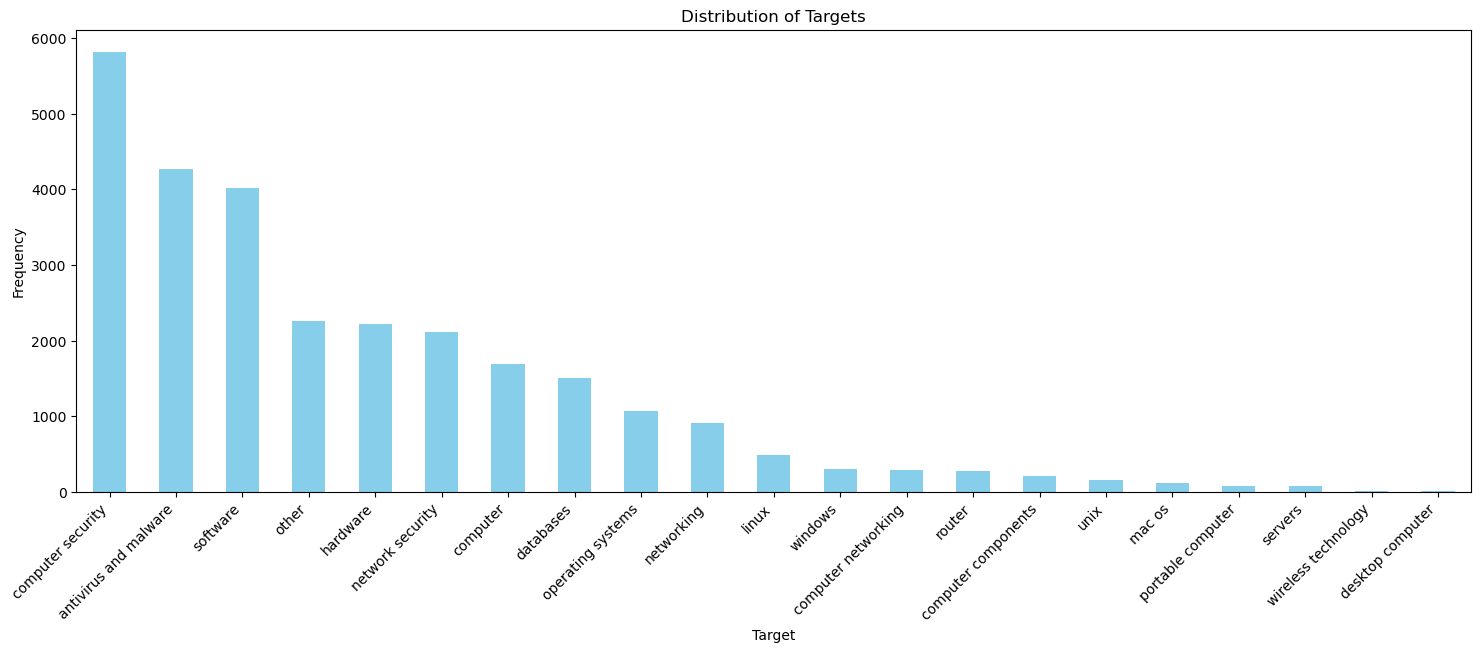

In [11]:
class_freq = Counter([item for sublist in categories_df['target'] for item in sublist])

print("Target Frequencies:")
for target, freq in class_freq.most_common():
    print(f"{target}: {freq}")

_, ax = plt.subplots(figsize=(18, 6))
pd.Series(data=class_freq).sort_values(ascending=False).plot(kind='bar', color='skyblue')
plt.title('Distribution of Targets')
plt.xlabel('Target')
plt.ylabel('Frequency')
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

Target Frequencies:
('other',): 2255
('computer security', 'antivirus and malware'): 1702
('computer security', 'network security'): 719
('software',): 454
('software', 'computer security', 'antivirus and malware'): 446
('hardware', 'computer'): 377
('software', 'databases'): 349
('computer security', 'network security', 'antivirus and malware'): 342
('hardware', 'computer', 'computer security', 'antivirus and malware'): 336
('software', 'computer security', 'network security'): 253
('networking',): 208
('software', 'databases', 'antivirus and malware', 'computer security'): 196
('hardware', 'software', 'computer security', 'antivirus and malware', 'computer'): 189
('software', 'computer security', 'antivirus and malware', 'databases'): 168
('hardware', 'software', 'computer'): 124
('operating systems', 'software', 'databases', 'linux'): 120
('networking', 'software'): 105
('software', 'computer security', 'network security', 'antivirus and malware'): 104
('software', 'computer securit

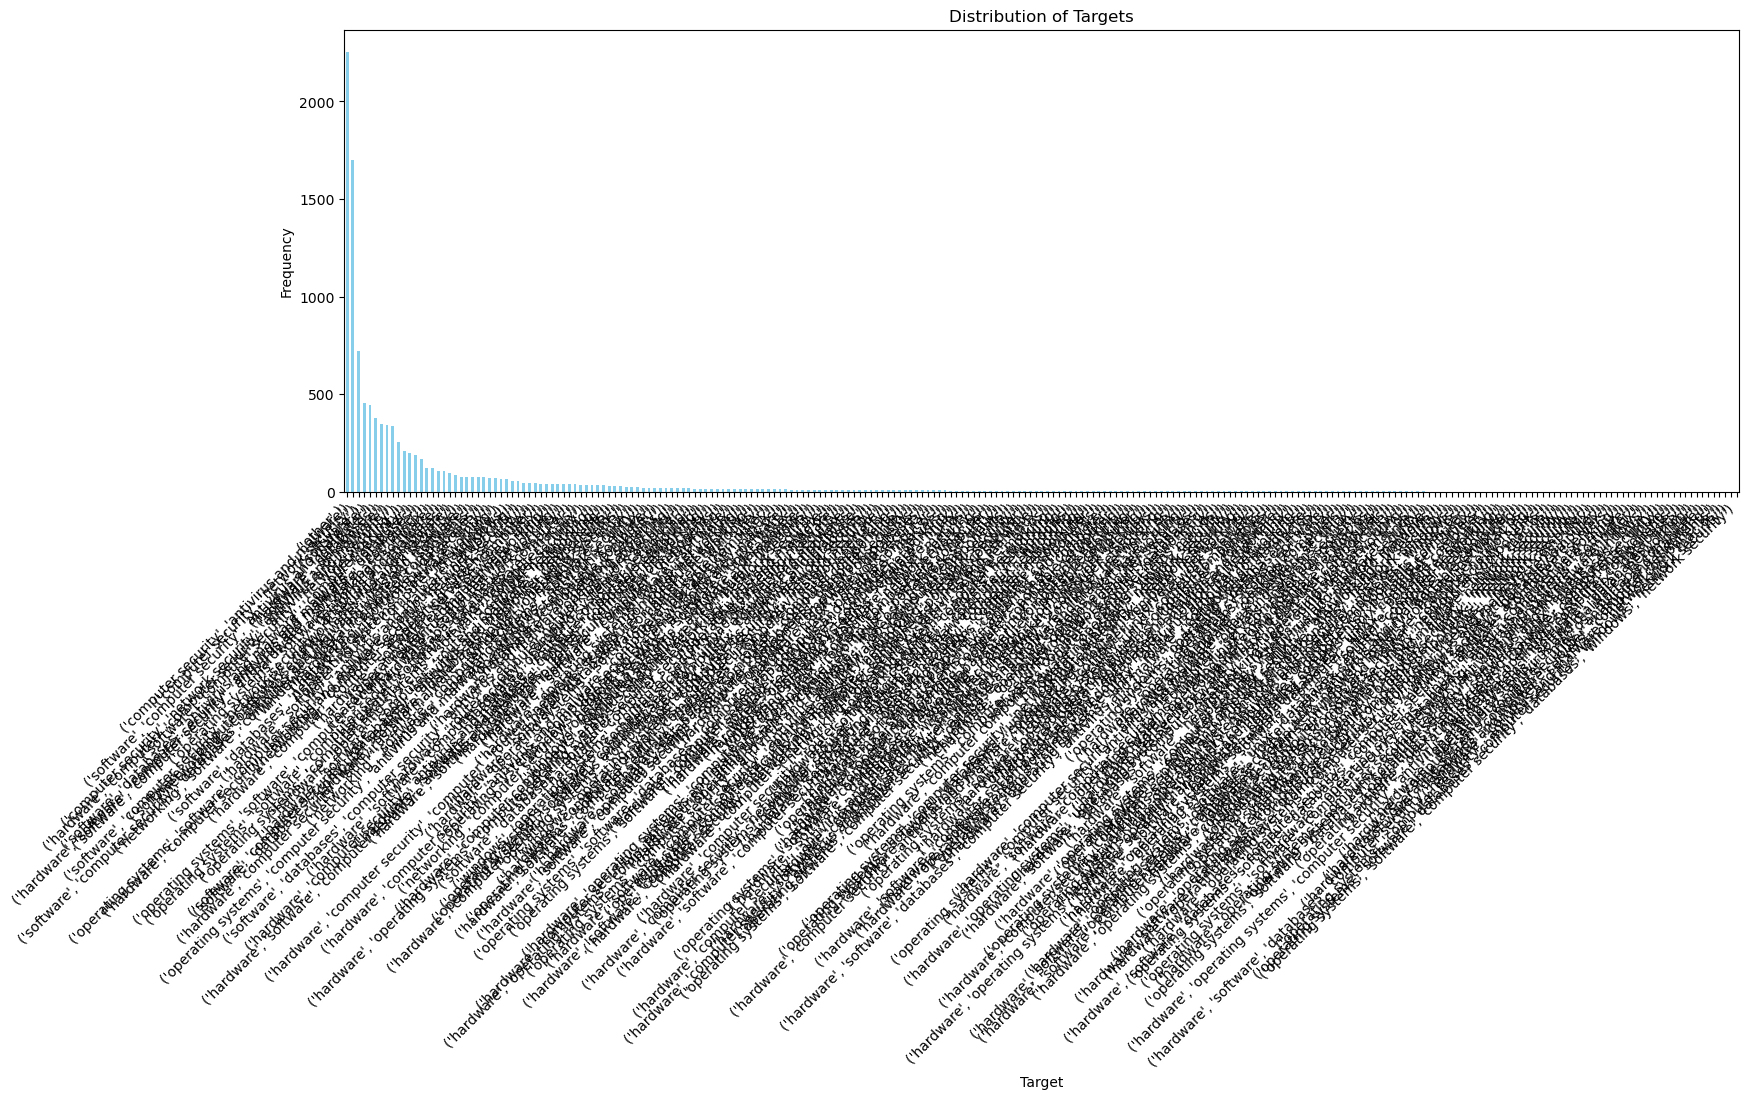

Number of targets to subsample:	158


In [12]:
target_freq = Counter(tuple(item) for item in categories_df['target'])
cut = len(target_freq)

print("Target Frequencies:")
for target, freq in target_freq.most_common()[:cut]:
    print(f"{target}: {freq}")

_, ax = plt.subplots(figsize=(18, 6))

(pd.Series(data={str(k): v for k, v in target_freq.most_common()[:cut]})
 .sort_values(ascending=False)
 .plot(kind='bar', color='skyblue'))

plt.title('Distribution of Targets')
plt.xlabel('Target')
plt.ylabel('Frequency')
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()
print(f'Number of targets to subsample:\t{sum([1 if v < 10 else 0 for v in target_freq.values()])}')

In [13]:
mlb = MultiLabelBinarizer()
y = mlb.fit_transform(y=categories_df['target'])
labels_map, _ = np.unique(ar=y, axis=0, return_inverse=True)

Target Frequencies:
('other',): 2255
('computer security', 'antivirus and malware'): 1702
('computer security', 'network security'): 719
('software',): 454
('software', 'computer security', 'antivirus and malware'): 446
('hardware', 'computer'): 377
('software', 'databases'): 349
('computer security', 'network security', 'antivirus and malware'): 342
('hardware', 'computer', 'computer security', 'antivirus and malware'): 336
('software', 'computer security', 'network security'): 253
('networking',): 208
('software', 'databases', 'antivirus and malware', 'computer security'): 196
('hardware', 'software', 'computer security', 'antivirus and malware', 'computer'): 189
('software', 'computer security', 'antivirus and malware', 'databases'): 168
('hardware', 'software', 'computer'): 124
('operating systems', 'software', 'databases', 'linux'): 120
('networking', 'software'): 105
('software', 'computer security', 'network security', 'antivirus and malware'): 104
('software', 'computer securit

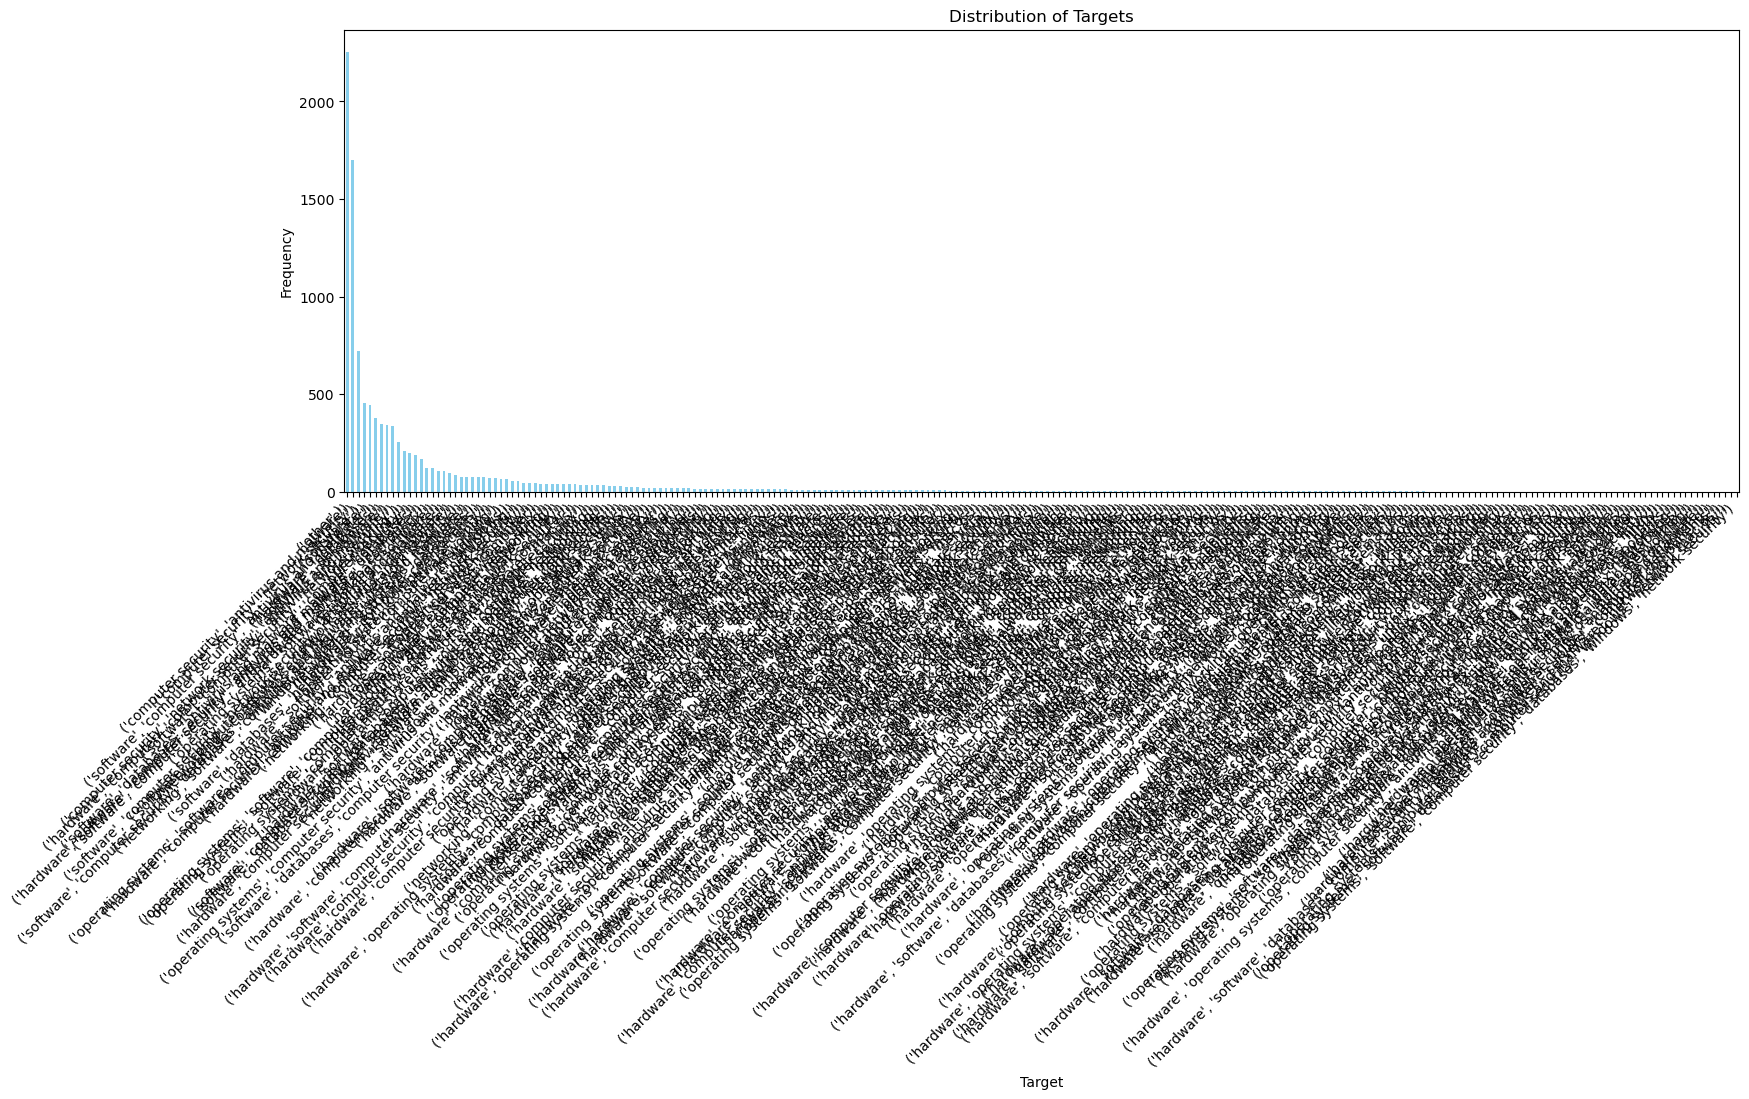

Updated Target Frequencies:
('other',): 2255
('computer security', 'antivirus and malware'): 1702
('computer security', 'network security'): 719
('software',): 454
('software', 'computer security', 'antivirus and malware'): 446
('hardware', 'computer'): 377
('software', 'databases'): 349
('computer security', 'network security', 'antivirus and malware'): 342
('hardware', 'computer', 'computer security', 'antivirus and malware'): 336
('software', 'computer security', 'network security'): 253
('networking',): 208
('software', 'databases', 'antivirus and malware', 'computer security'): 196
('hardware', 'software', 'computer security', 'antivirus and malware', 'computer'): 189
('software', 'computer security', 'antivirus and malware', 'databases'): 168
('hardware', 'software', 'computer'): 124
('operating systems', 'software', 'databases', 'linux'): 120
('networking', 'software'): 105
('software', 'computer security', 'network security', 'antivirus and malware'): 104
('software', 'computer

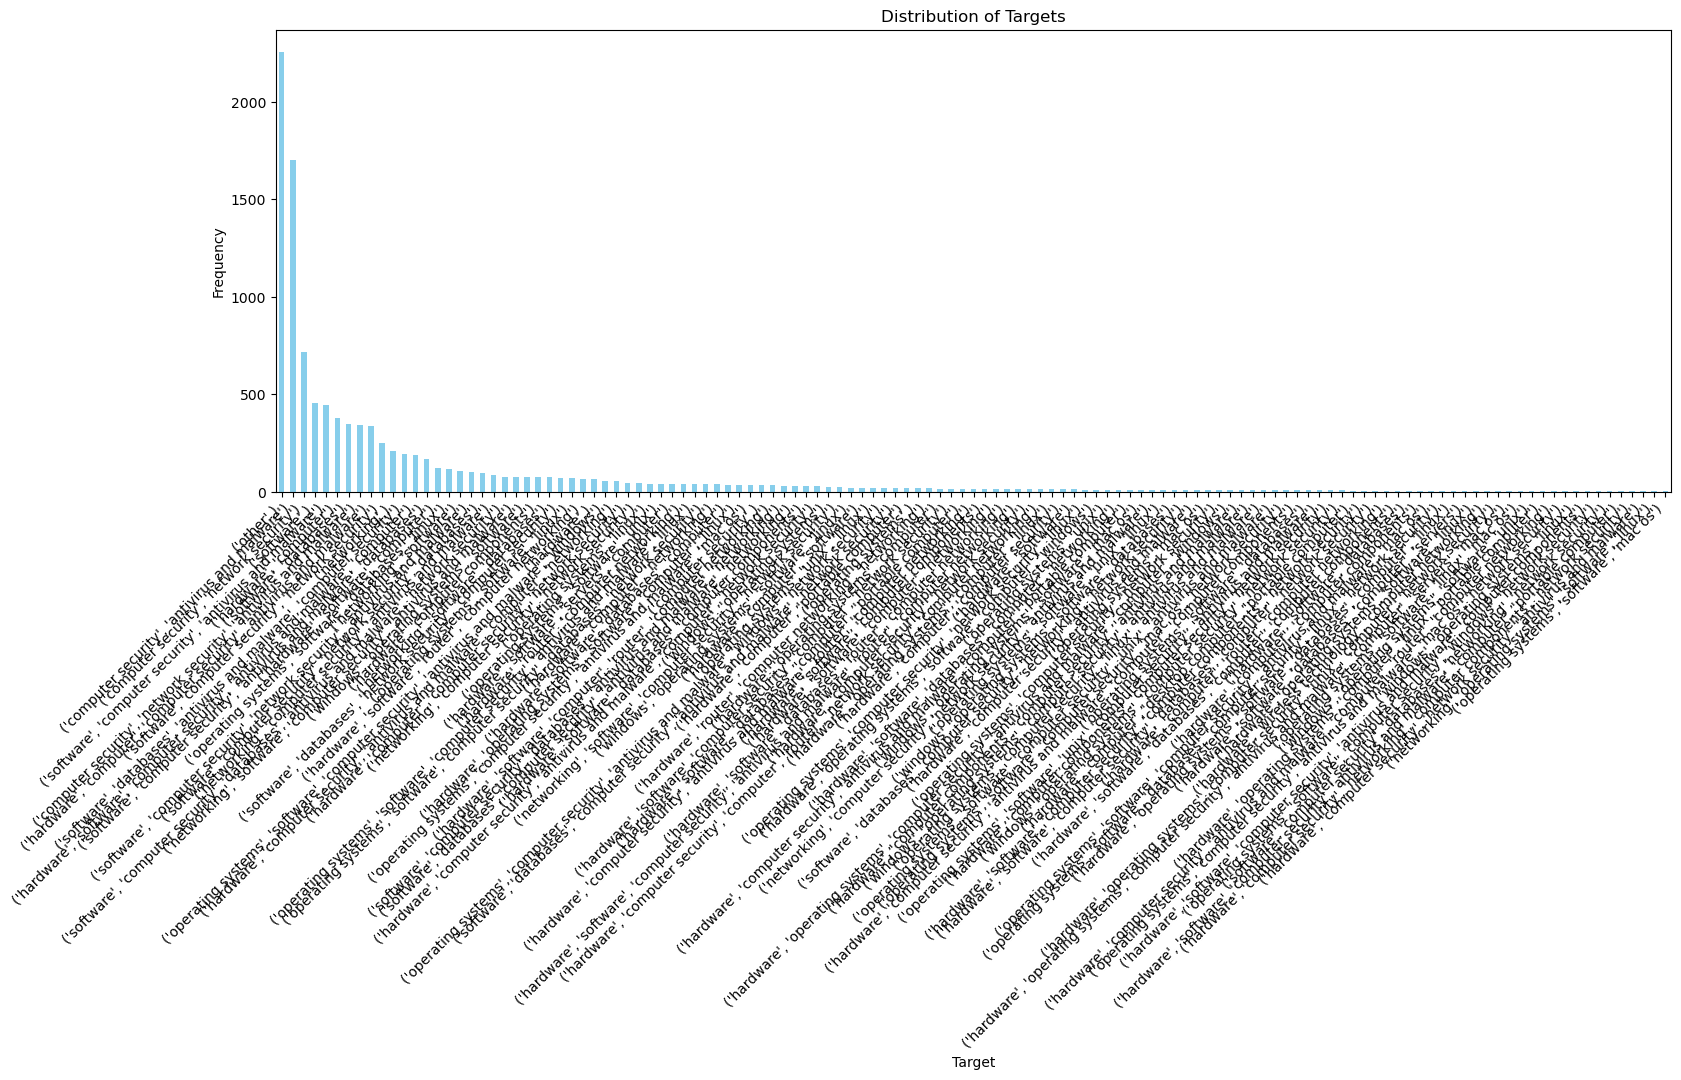

In [14]:
target_freq = Counter(tuple(item) for item in categories_df['target'])

print("Target Frequencies:")
for target, freq in target_freq.most_common():
    print(f"{target}: {freq}")

_, ax = plt.subplots(figsize=(18, 6))
(pd.Series(data={str(k): v for k, v in target_freq.items()})
 .sort_values(ascending=False)
 .plot(kind='bar', color='skyblue'))
plt.title('Distribution of Targets')
plt.xlabel('Target')
plt.ylabel('Frequency')
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

valid_targets = {target for target, freq in target_freq.items() if freq >= 5}

# Filter the DataFrame to keep only valid targets
categories_df = categories_df[categories_df['target'].apply(lambda x: tuple(x) in valid_targets)]

# Reset the index (optional)
categories_df = categories_df.reset_index(drop=True)

# Print the updated target frequencies
updated_target_freq = Counter(tuple(item) for item in categories_df['target'])
print("Updated Target Frequencies:")
for target, freq in updated_target_freq.most_common():
    print(f"{target}: {freq}")

_, ax = plt.subplots(figsize=(18, 6))
(pd.Series(data={str(k): v for k, v in updated_target_freq.items()})
 .sort_values(ascending=False)
 .plot(kind='bar', color='skyblue'))
plt.title('Distribution of Targets')
plt.xlabel('Target')
plt.ylabel('Frequency')
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

In [15]:
_, y_mcp = np.unique(ar=mlb.transform(categories_df['target']), axis=0, return_inverse=True)
X_train_val, X_test = train_test_split(
    categories_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=y_mcp
)

In [16]:
with open(DATA_DIR / 'tweets-dataset' / 'categories_train.csv', 'wb') as f:
    X_train_val.to_csv(path_or_buf=f)

with open(DATA_DIR / 'tweets-dataset' / 'categories_test.csv', 'wb') as f:
    X_test.to_csv(path_or_buf=f)